# Evaluasi Segmentasi Baris Tulisan — YOLO11x-OBB: Baseline vs Fine-tuning All

Notebook ini membandingkan dua model dengan **pipeline metrik yang identik** (pengaturan inferensi tiap model mengikuti konfigurasinya masing-masing, lihat `INFER_CFG`):

| Label | Keterangan |
|---|---|
| `Pretrained` | Baseline: bobot `best.pt` dari Hugging Face (`WARAJA/Tzefa-Line-Segmentation-YOLO`), satu kelas `line`, tanpa fine-tuning pada dataset ini (evaluasi *class-agnostic*) |
| `FT-All` | Fine-tuning **semua layer** pada dataset baris tulisan |
| `FT-FREEZE-ENCODER` | Fine-tuning **layer decoder** dan membekukan **encoder** pada dataset baris tulisan |

**Alur notebook**
1. Setup & konfigurasi
2. **Baseline: inferensi satu foto** (model pretrained)
3. Menyiapkan bobot kedua model
4. Fungsi metrik
5. Inferensi seluruh split + ground truth
6. **Perbandingan metrik** Baseline vs FT-All (+ selisih)
7. **Grafik**: batang perbandingan, kurva Precision–Recall, F1 vs conf
8. **Visualisasi berdampingan**: Ground Truth | Baseline | FT-All

**Metrik** (semua dihitung sendiri dari prediksi vs ground truth, bukan `model.val()`, agar kedua model dievaluasi dengan pipeline yang identik dan *class-agnostic*, tidak bergantung pada nama kelas masing-masing model):
- **Tingkat area (pixel, *micro*)**: IoU, Precision, Recall, F1 dari gabungan prediksi vs gabungan GT yang dirasterisasi.
- **Tingkat objek (poligon terotasi exact)**: Precision / Recall / F1 @IoU 0,50, matched mIoU, mAP@50, mAP@50:95.

Titik operasi utama: **best-F1** per model per split. Tabel pembanding tambahan memakai conf tetap 0,25. mAP tidak bergantung ambang.

## 1. Setup & konfigurasi

In [1]:
!pip install -q shapely lxml tqdm huggingface_hub

In [2]:
import importlib, subprocess, sys, warnings, logging
for pkg, mod in [("ultralytics", "ultralytics"), ("shapely>=2.0", "shapely"), ("pyyaml", "yaml")]:
    try: importlib.import_module(mod)
    except ImportError: subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
import shapely
assert int(shapely.__version__.split(".")[0]) >= 2, "Butuh shapely>=2.0 (pip install -U shapely, lalu restart kernel)."

import os, re, json, pickle, hashlib, random
from pathlib import Path
import numpy as np, cv2, yaml, torch
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display, Markdown
from tqdm.auto import tqdm
from huggingface_hub import hf_hub_download
from ultralytics import YOLO

warnings.filterwarnings("ignore")
logging.getLogger("ultralytics").setLevel(logging.ERROR)
pd.set_option("display.width", 200, "display.max_columns", 50)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [3]:
# ============================ KONFIGURASI ============================
# --- Baseline (pretrained) dari Hugging Face ---
HF_REPO_ID  = "WARAJA/Tzefa-Line-Segmentation-YOLO"
HF_FILENAME = "best.pt"

# --- Lokasi kerja & dataset ---
WORK_DIR       = "/kaggle/working"
PROJECT        = f"{WORK_DIR}/runs"
DATASET_ROOT   = None        # None = cari otomatis (folder berisi data.yaml + images/ + labels/)
EVAL_SPLITS    = ["val", "test"]
MAIN_SPLIT     = "test"      # split untuk tabel utama, grafik, dan visualisasi

# --- Inferensi satu foto (bagian 2) ---
# SAMPLE_IMAGE   = "/kaggle/input/datasets/gracians/greek-dataset-yolo-obb/images/test/15_01_0053_0011_f_5v_res.png"
SAMPLE_IMAGE = "/kaggle/input/datasets/gracians/greek-dataset-yolo-obb-2/dataset_yolo_obb_2/images/test/15_01_0053_0038_f_19r_res.png"
DEMO_IMGSZ, DEMO_CONF, DEMO_NMS_IOU = 640, 0.2, 0.2

# --- Model yang dibandingkan: label -> slug folder notebook training di Kaggle (None = bobot baseline) ---
BASE, FT, FREEZE_ENC = "Pretrained", "FT-All", "FREEZE-ENCODER"
MODEL_SLUGS = {
    BASE: None,
    FT:   "yolov11-obb-finetuning-all",
    FREEZE_ENC: "yolov11-obb-finetuning-encoder-only"
}
MANUAL_WEIGHTS = {}          # override opsional: {"FT-All": "/path/ke/best.pt"}

# --- Pengaturan evaluasi ---
BATCH          = 4
DEVICE         = 0 if torch.cuda.is_available() else "cpu"
CONF_MIN, MAX_DET, CONF_FIXED = 0.001, 300, 0.25      # conf rendah agar kurva PR & pencarian ambang best-F1 lengkap

# Pengaturan inferensi per model. Baseline memakai konfigurasi aslinya (imgsz & NMS-IoU dari demo bagian 2);
# FT-All memakai konfigurasi training-nya. conf, max_det, dan agnostic NMS sama untuk keduanya.
INFER_CFG = {
    BASE: dict(imgsz=DEMO_IMGSZ, iou=DEMO_NMS_IOU),   # 640, 0.2
    # FT:   dict(imgsz=1024,       iou=0.7),
    FT: dict(imgsz=DEMO_IMGSZ, iou=DEMO_NMS_IOU), 
    FREEZE_ENC: dict(imgsz=DEMO_IMGSZ, iou=DEMO_NMS_IOU), 
}
IOU_THRS       = np.linspace(0.5, 0.95, 10)
RASTER_MAX_SIDE = 2048
USE_CACHE      = True

# --- Visualisasi ---
N_VIS, SEED    = 4, 42       # jumlah halaman pada perbandingan berdampingan
OVERLAY_GT_ON_PRED = True    # True = GT (hijau) ikut digambar di panel model, seperti pada Kraken BLLA

# --- Folder output ---
OUT_DIR   = Path(f"{WORK_DIR}/evaluation"); OUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR = OUT_DIR / "cache";        CACHE_DIR.mkdir(exist_ok=True)
VIS_DIR   = OUT_DIR / "qualitative";  VIS_DIR.mkdir(exist_ok=True)
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp", ".webp"}

# Warna tetap agar konsisten di semua grafik
COLORS  = {BASE: "#9e9e9e", FT: "#1f77b4", FREEZE_ENC: "#123455"}                                    # grafik batang & kurva
OVERLAY = {"Ground Truth": "#00c800", BASE: "#e53935", FT: "#1f77b4", FREEZE_ENC: "#123455"}         # overlay kotak pada gambar

In [4]:
def find_data_yaml():
    for base in (Path(WORK_DIR), Path("/kaggle/input")):
        if base.exists():
            for p in sorted(base.rglob("data.yaml")):
                if (p.parent / "images").is_dir() and (p.parent / "labels").is_dir():
                    return p
    return None

if DATASET_ROOT:
    ROOT = Path(DATASET_ROOT)
else:
    _y = find_data_yaml(); assert _y is not None, "Dataset tidak ditemukan; set DATASET_ROOT."
    ROOT = _y.parent

IMG_PATHS = {s: sorted(p for p in (ROOT / "images" / s).iterdir() if p.suffix.lower() in IMAGE_EXTS)
             for s in EVAL_SPLITS if (ROOT / "images" / s).is_dir()}
EVAL_SPLITS = [s for s in EVAL_SPLITS if s in IMG_PATHS]

_cfg = yaml.safe_load((ROOT / "data.yaml").read_text()) if (ROOT / "data.yaml").exists() else {"names": {0: "line"}}
_cfg["path"] = str(ROOT.resolve())
for s in ("train", "val", "test"): _cfg[s] = f"images/{s}"
DATA_YAML = Path(f"{WORK_DIR}/data_eval_runtime.yaml"); DATA_YAML.write_text(yaml.safe_dump(_cfg, sort_keys=False))

print(f"Dataset : {ROOT}")
print("Split   :", {s: len(v) for s, v in IMG_PATHS.items()})

Dataset : /kaggle/input/datasets/gracians/greek-dataset-yolo-obb-2/dataset_yolo_obb_2
Split   : {'val': 25, 'test': 27}


## 2. Baseline: inferensi satu foto (Pretrained)
Model baseline diunduh dari Hugging Face lalu dijalankan pada **satu foto** untuk melihat perilaku awalnya sebelum dibandingkan dengan hasil fine-tuning.
Baseline memakai satu kelas bernama `line` (`names = {0: 'line'}`); label kelas dan confidence ikut ditampilkan.

In [5]:
BASELINE_PATH = hf_hub_download(repo_id=HF_REPO_ID, filename=HF_FILENAME, local_dir=f"{WORK_DIR}/yolov11-obb-base")
print("Model baseline tersimpan di:", BASELINE_PATH)
# (Warning "unauthenticated requests to the HF Hub" aman diabaikan.)

best.pt: reconstructing file:   0%|          |  0.00B /  118MB            

best.pt: downloading bytes:           |  0.00B            

Model baseline tersimpan di: /kaggle/working/yolov11-obb-base/best.pt


Foto   : 15_01_0053_0038_f_19r_res.png
Kelas  : {0: 'line'}


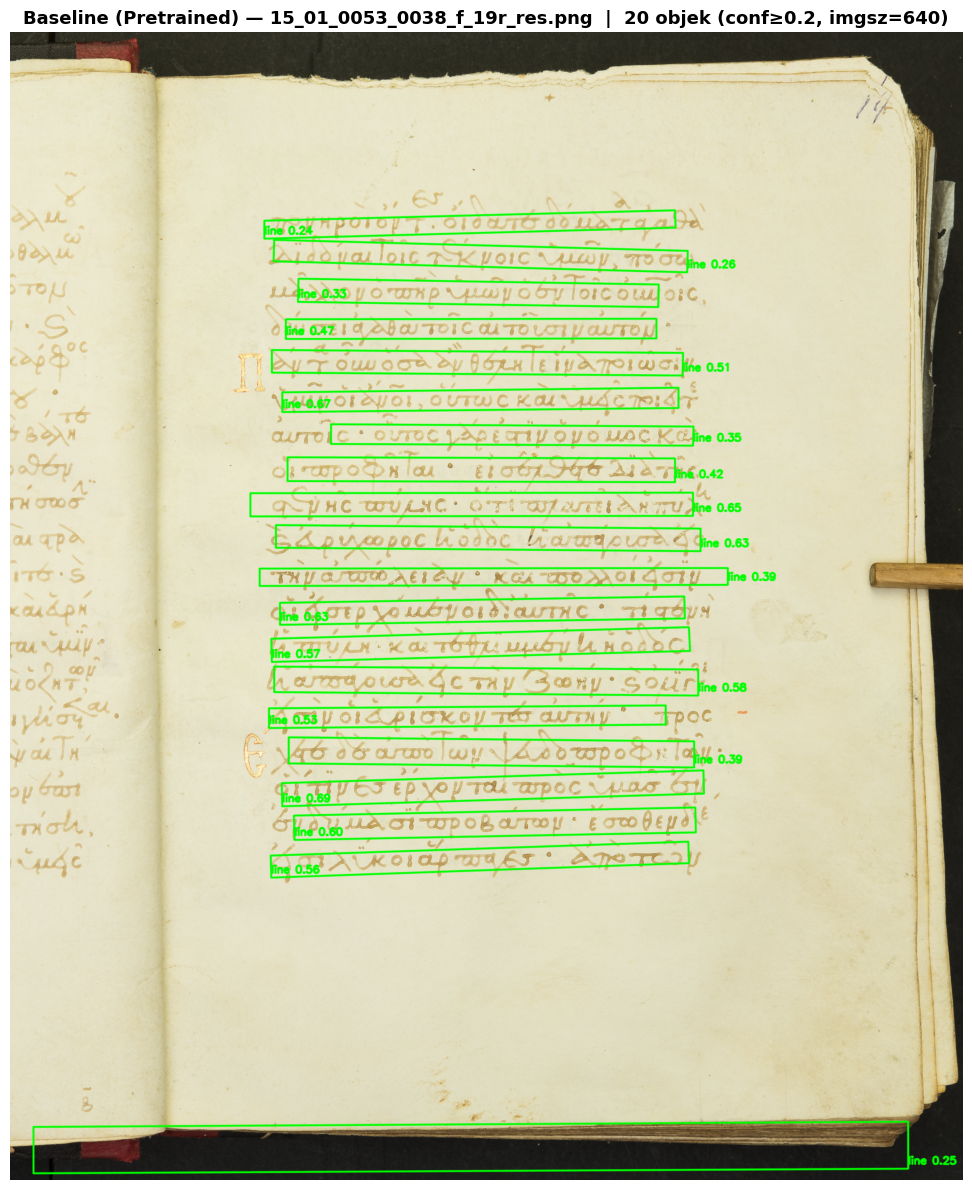

In [6]:
def draw_yolo_obb(results, line_color=(0, 255, 0), thickness=2, show_conf=True, font_scale=0.6, title=None):
    """Gambar OBB hasil prediksi Ultralytics pada gambar asli dan tampilkan dengan matplotlib."""
    result = results[0]
    image = result.orig_img.copy()
    obb = result.obb
    n = 0 if obb is None else len(obb)

    if n:
        polygons = obb.xyxyxyxy.cpu().numpy()
        confidences = obb.conf.cpu().numpy()
        class_ids = obb.cls.cpu().numpy().astype(int)
        for polygon, conf, cls_id in zip(polygons, confidences, class_ids):
            points = polygon.astype(np.int32)
            cv2.polylines(image, [points], isClosed=True, color=line_color, thickness=thickness, lineType=cv2.LINE_AA)
            label = result.names[cls_id] + (f" {conf:.2f}" if show_conf else "")
            x, y = points[0]
            cv2.putText(image, label, (int(x), max(int(y) - 8, 15)), cv2.FONT_HERSHEY_SIMPLEX,
                        font_scale, line_color, 2, cv2.LINE_AA)

    plt.figure(figsize=(15, 12))
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title or f"{n} objek terdeteksi", fontsize=13, fontweight="bold")
    plt.axis("off"); plt.tight_layout(); plt.show()
    return image


# Pilih foto contoh; bila path di konfigurasi tidak ada, pakai foto pertama dari MAIN_SPLIT
sample_path = SAMPLE_IMAGE if (SAMPLE_IMAGE and os.path.exists(SAMPLE_IMAGE)) else str(IMG_PATHS[MAIN_SPLIT][0])

baseline_model = YOLO(BASELINE_PATH)
demo_results = baseline_model.predict(sample_path, imgsz=DEMO_IMGSZ, conf=DEMO_CONF, iou=DEMO_NMS_IOU, verbose=False)

print("Foto   :", Path(sample_path).name)
print("Kelas  :", demo_results[0].names)
_ = draw_yolo_obb(demo_results, title=f"Baseline (Pretrained) — {Path(sample_path).name}  |  "
                                      f"{len(demo_results[0].obb)} objek (conf≥{DEMO_CONF}, imgsz={DEMO_IMGSZ})")
del baseline_model; torch.cuda.empty_cache()

In [7]:
demo_results

[ultralytics.engine.results.Results object with attributes:
 
 boxes: None
 colors: None
 depth: None
 keypoints: None
 masks: None
 names: {0: 'line'}
 obb: ultralytics.engine.results.OBB object
 orig_img: array([[[32, 42, 41],
         [33, 43, 43],
         [34, 44, 44],
         ...,
         [32, 40, 41],
         [32, 40, 41],
         [31, 39, 40]],
 
        [[31, 41, 40],
         [32, 42, 41],
         [31, 41, 40],
         ...,
         [32, 40, 41],
         [32, 40, 41],
         [31, 39, 39]],
 
        [[35, 46, 46],
         [34, 45, 44],
         [32, 43, 43],
         ...,
         [31, 38, 39],
         [30, 37, 38],
         [30, 38, 38]],
 
        ...,
 
        [[22, 22, 22],
         [22, 23, 23],
         [21, 22, 22],
         ...,
         [25, 28, 28],
         [26, 29, 28],
         [27, 30, 29]],
 
        [[24, 24, 24],
         [24, 25, 25],
         [24, 24, 24],
         ...,
         [24, 26, 26],
         [25, 27, 27],
         [27, 30, 29]],
 
    

## 3. Menyiapkan bobot kedua model
`Pretrained` memakai bobot dari bagian 2; `FT-All` dicari otomatis dari folder hasil training (`best.pt` terbaru), atau diisi manual lewat `MANUAL_WEIGHTS`.

In [8]:
def find_best(slug):
    """best.pt yang path-nya memuat komponen folder bernama persis `slug`."""
    cands = []
    for base in (Path(PROJECT), Path(WORK_DIR), Path("/kaggle/input")):
        if base.exists():
            cands += [p for p in base.rglob("best.pt") if p.parent.name == "weights" and slug in p.parts]
    assert cands, f"best.pt untuk '{slug}' tidak ditemukan. Isi MANUAL_WEIGHTS."
    return str(max(cands, key=lambda p: p.stat().st_mtime))

MODELS = {}
for name, slug in MODEL_SLUGS.items():
    MODELS[name] = MANUAL_WEIGHTS.get(name) or (BASELINE_PATH if slug is None else find_best(slug))

display(pd.DataFrame({"bobot": MODELS}).rename_axis("model"))

,bobot
model,
Pretrained,/kaggle/working/yolov11-obb-base/best.pt
FT-All,/kaggle/input/notebooks/gracians/yolov11-obb-f...
FREEZE-ENCODER,/kaggle/input/notebooks/gracians/yolov11-obb-f...


In [9]:
# Verifikasi nama kelas kedua model harus sama dengan pelabelan dataset: {0: 'line'}
for name, w in MODELS.items():
    names = YOLO(w).names
    print(f"{name:12s} names = {names}")
    assert names == {0: "line"}, f"{name}: nama kelas tidak sesuai pola ({names})"
print("Nama kelas OK ✔")

Pretrained   names = {0: 'line'}
FT-All       names = {0: 'line'}
FREEZE-ENCODER names = {0: 'line'}
Nama kelas OK ✔


## 4. Fungsi metrik
IoU poligon terotasi exact, pencocokan greedy, AP 101-titik, metrik area, dan pemilihan ambang best-F1. (Logika tidak berubah dari versi sebelumnya.)

In [10]:
def read_gt_file(path, W, H):
    rows = []
    if Path(path).exists():
        for line in Path(path).read_text().splitlines():
            t = line.split()
            if len(t) == 9: rows.append([float(x) for x in t[1:]])
    if not rows: return np.zeros((0, 4, 2))
    return np.asarray(rows).reshape(-1, 4, 2) * np.array([W, H])

def rot_iou_matrix(P, G):
    N, M_ = len(P), len(G)
    iou = np.zeros((N, M_), np.float32)
    if N == 0 or M_ == 0: return iou
    pmin, pmax, gmin, gmax = P.min(1), P.max(1), G.min(1), G.max(1)
    ov = ((pmin[:, None, 0] < gmax[None, :, 0]) & (pmax[:, None, 0] > gmin[None, :, 0]) &
          (pmin[:, None, 1] < gmax[None, :, 1]) & (pmax[:, None, 1] > gmin[None, :, 1]))
    ii, jj = np.nonzero(ov)
    if len(ii) == 0: return iou
    pp = shapely.make_valid(shapely.polygons(P)); gp = shapely.make_valid(shapely.polygons(G))
    pa, ga = shapely.area(pp), shapely.area(gp)
    inter = shapely.area(shapely.intersection(pp[ii], gp[jj]))
    union = pa[ii] + ga[jj] - inter
    iou[ii, jj] = np.where(union > 0, inter / np.maximum(union, 1e-12), 0)
    return iou

def match_image(iou, thrs):
    N, M_ = iou.shape
    tp = np.zeros((N, len(thrs)), bool); mi = np.zeros(N)
    if N == 0 or M_ == 0: return tp, mi
    for ti, t in enumerate(thrs):
        used = np.zeros(M_, bool)
        for i in range(N):
            cand = np.where(used, -1.0, iou[i]); j = int(cand.argmax())
            if cand[j] >= t:
                used[j] = True; tp[i, ti] = True
                if ti == 0: mi[i] = cand[j]
    return tp, mi

def build_eval(preds, gts, thrs=None):
    thrs = IOU_THRS if thrs is None else thrs
    C_, T_, MI, nGT = [], [], [], 0
    for d in preds:
        G = gts[d["stem"]]; nGT += len(G)
        tp, mi = match_image(rot_iou_matrix(d["quads"], G), thrs)
        C_.append(d["conf"]); T_.append(tp); MI.append(mi)
    return dict(conf=np.concatenate(C_) if C_ else np.zeros(0),
                tp=np.vstack(T_) if T_ else np.zeros((0, len(thrs)), bool),
                miou=np.concatenate(MI) if MI else np.zeros(0), nGT=nGT)

def pr_curve(conf, tp, nGT):
    order = np.argsort(-conf); t = tp[order]
    ctp, cfp = np.cumsum(t), np.cumsum(~t)
    return conf[order], ctp / max(nGT, 1e-16), ctp / np.maximum(ctp + cfp, 1e-16)

def compute_ap(recall, precision):
    mrec = np.concatenate(([0.0], recall, [1.0])); mpre = np.concatenate(([1.0], precision, [0.0]))
    mpre = np.flip(np.maximum.accumulate(np.flip(mpre)))
    x = np.linspace(0, 1, 101); trap = getattr(np, "trapezoid", None) or np.trapz
    return float(trap(np.interp(x, mrec, mpre), x))

def ap_per_thr(ev):
    if ev["nGT"] == 0: return np.full(ev["tp"].shape[1], np.nan)
    out = []
    for ti in range(ev["tp"].shape[1]):
        _, r, p = pr_curve(ev["conf"], ev["tp"][:, ti], ev["nGT"]); out.append(compute_ap(r, p) if len(r) else 0.0)
    return np.array(out)

def best_f1_conf(ev, fallback=0.25):
    if len(ev["conf"]) == 0 or ev["nGT"] == 0: return fallback
    c, r, p = pr_curve(ev["conf"], ev["tp"][:, 0], ev["nGT"])
    f1 = 2 * p * r / np.maximum(p + r, 1e-16)
    return float(c[int(np.argmax(f1))])

def object_metrics(ev, thr):
    m = ev["conf"] >= thr; tp0 = ev["tp"][:, 0]
    TP = int((tp0 & m).sum()); FP = int(m.sum()) - TP; FN = ev["nGT"] - TP
    P = TP / (TP + FP) if TP + FP else 0.0; R = TP / ev["nGT"] if ev["nGT"] else 0.0
    F1 = 2 * P * R / (P + R) if P + R else 0.0
    mi = ev["miou"][m & tp0]
    return dict(Obj_Precision=P, Obj_Recall=R, Obj_F1=F1, Matched_mIoU=float(mi.mean()) if len(mi) else 0.0,
                Obj_TP=TP, Obj_FP=FP, Obj_FN=FN)

def pixel_metrics(preds, gts, thr, raster_max_side=2048):
    TP = FP = FN = 0.0; per = []
    for d in preds:
        Q = d["quads"][d["conf"] >= thr]; G = gts[d["stem"]]; W, H = d["W"], d["H"]
        s = min(1.0, raster_max_side / max(W, H)); w, h = max(1, round(W * s)), max(1, round(H * s))
        pm = np.zeros((h, w), np.uint8); gm = np.zeros((h, w), np.uint8)
        if len(Q): cv2.fillPoly(pm, [np.round(q * s).astype(np.int32) for q in Q], 1)
        if len(G): cv2.fillPoly(gm, [np.round(g * s).astype(np.int32) for g in G], 1)
        tp = int(np.count_nonzero(pm & gm)); fp = int(np.count_nonzero(pm)) - tp; fn = int(np.count_nonzero(gm)) - tp
        k = 1.0 / (s * s); TP += tp * k; FP += fp * k; FN += fn * k
        u = tp + fp + fn
        per.append(dict(stem=d["stem"], Pixel_IoU=tp / u if u else np.nan,
                        Pixel_Precision=tp / (tp + fp) if tp + fp else np.nan,
                        Pixel_Recall=tp / (tp + fn) if tp + fn else np.nan))
    P = TP / (TP + FP) if TP + FP else 0.0; R = TP / (TP + FN) if TP + FN else 0.0
    out = dict(Pixel_IoU=TP / (TP + FP + FN) if TP + FP + FN else 0.0, Pixel_Precision=P, Pixel_Recall=R,
               Pixel_F1=2 * P * R / (P + R) if P + R else 0.0)
    pdf = pd.DataFrame(per)
    out["Pixel_IoU_macro"] = float(pdf["Pixel_IoU"].mean()) if len(pdf) else np.nan
    return out, pdf

def summarize(ev, preds, gts, op, raster_max_side=2048):
    thr = best_f1_conf(ev) if op == "best_f1" else float(op)
    ap = ap_per_thr(ev)
    row = dict(Conf_threshold=thr, mAP50=ap[0], mAP50_95=float(np.nanmean(ap)),
               n_images=len(preds), n_GT=ev["nGT"], n_pred_at_thr=int((ev["conf"] >= thr).sum()))
    row.update(object_metrics(ev, thr))
    pm, pdf = pixel_metrics(preds, gts, thr, raster_max_side)
    row.update(pm)
    return row, pdf

## 5. Inferensi seluruh split & ground truth
Setiap model dijalankan dengan konfigurasinya sendiri (`INFER_CFG`): baseline `imgsz=640, NMS-IoU=0.2` (konfigurasi asli, sama dengan demo bagian 2), FT-All `imgsz=1024, NMS-IoU=0.7`. `conf=0.001`, `max_det`, dan NMS-agnostik sama untuk keduanya. Prediksi di-cache sehingga re-run cepat.

In [11]:
def run_inference(name, weights, split):
    key = hashlib.md5(f"{weights}|{os.path.getmtime(weights) if os.path.exists(weights) else 0}|{INFER_CFG[name]}|{MAX_DET}|{split}".encode()).hexdigest()[:10]
    cache = CACHE_DIR / f"{re.sub(r'[^A-Za-z0-9]+', '_', name)}_{split}_{key}.pkl"
    if USE_CACHE and cache.exists(): return pickle.loads(cache.read_bytes())
    model = YOLO(weights); out = []
    stream = model.predict(source=[str(p) for p in IMG_PATHS[split]], stream=True, imgsz=INFER_CFG[name]["imgsz"], conf=CONF_MIN, iou=INFER_CFG[name]["iou"],
                           max_det=MAX_DET, agnostic_nms=True, device=DEVICE, batch=BATCH, verbose=False)
    for r in tqdm(stream, total=len(IMG_PATHS[split]), desc=f"{name} / {split}", leave=False):
        H, W = r.orig_shape
        if r.obb is not None and len(r.obb):
            q = r.obb.xyxyxyxy.cpu().numpy().astype(np.float64); c = r.obb.conf.cpu().numpy().astype(np.float64)
        else: q, c = np.zeros((0, 4, 2)), np.zeros(0)
        o = np.argsort(-c)
        out.append(dict(stem=Path(r.path).stem, W=W, H=H, quads=q[o], conf=c[o]))
    del model; torch.cuda.empty_cache()
    cache.write_bytes(pickle.dumps(out)); return out

print("Pengaturan inferensi:", INFER_CFG)
PRED = {m: {} for m in MODELS}
for name, w in MODELS.items():
    for s in EVAL_SPLITS: PRED[name][s] = run_inference(name, w, s)

GT = {s: {d["stem"]: read_gt_file(ROOT / "labels" / s / f"{d['stem']}.txt", d["W"], d["H"]) for d in PRED[BASE][s]}
      for s in EVAL_SPLITS}
display(pd.DataFrame([dict(split=s, gambar=len(GT[s]), baris_GT=sum(len(g) for g in GT[s].values()),
                           gambar_tanpa_GT=sum(1 for g in GT[s].values() if len(g) == 0)) for s in EVAL_SPLITS]).set_index("split"))

Pengaturan inferensi: {'Pretrained': {'imgsz': 640, 'iou': 0.2}, 'FT-All': {'imgsz': 640, 'iou': 0.2}, 'FREEZE-ENCODER': {'imgsz': 640, 'iou': 0.2}}


Pretrained / val:   0%|          | 0/25 [00:00<?, ?it/s]

Pretrained / test:   0%|          | 0/27 [00:00<?, ?it/s]

FT-All / val:   0%|          | 0/25 [00:00<?, ?it/s]

FT-All / test:   0%|          | 0/27 [00:00<?, ?it/s]

FREEZE-ENCODER / val:   0%|          | 0/25 [00:00<?, ?it/s]

FREEZE-ENCODER / test:   0%|          | 0/27 [00:00<?, ?it/s]

,gambar,baris_GT,gambar_tanpa_GT
split,,,
val,25,488,0
test,27,537,0


## 6. Perbandingan metrik: Baseline vs Fine-tuning All
Tabel per split pada titik operasi **best-F1** (hijau = terbaik per kolom), ditambah baris **selisih (FT-All − Pretrained)**. Nilai selisih positif berarti fine-tuning lebih baik.

In [12]:
EVAL, ROWS, PER_IMAGE = {m: {} for m in MODELS}, [], []
for name in MODELS:
    for s in EVAL_SPLITS:
        EVAL[name][s] = build_eval(PRED[name][s], GT[s])
        for op in ("best_f1", "fixed"):
            row, pdf = summarize(EVAL[name][s], PRED[name][s], GT[s], "best_f1" if op == "best_f1" else CONF_FIXED, RASTER_MAX_SIDE)
            ROWS.append(dict(split=s, model=name, operating_point=op, **row))
            if op == "best_f1":
                pdf.insert(0, "split", s); pdf.insert(0, "model", name); PER_IMAGE.append(pdf)

RES = pd.DataFrame(ROWS)
RES.to_csv(OUT_DIR / "evaluation_summary.csv", index=False)
pd.concat(PER_IMAGE).to_csv(OUT_DIR / "per_image_pixel_metrics.csv", index=False)

PIXEL_COLS  = ["Pixel_IoU", "Pixel_Precision", "Pixel_Recall", "Pixel_F1", "Pixel_IoU_macro"]
OBJECT_COLS = ["Obj_Precision", "Obj_Recall", "Obj_F1", "Matched_mIoU", "mAP50", "mAP50_95"]
NICE = {"Pixel_IoU": "IoU", "Pixel_Precision": "Precision", "Pixel_Recall": "Recall", "Pixel_F1": "F1",
        "Pixel_IoU_macro": "IoU (rata2/gambar)", "Obj_Precision": "Precision", "Obj_Recall": "Recall",
        "Obj_F1": "F1", "Matched_mIoU": "Matched mIoU", "mAP50": "mAP@50", "mAP50_95": "mAP@50:95"}
DELTA = f"Selisih ({FT} − {BASE})"

def comparison_table(split, op):
    d = RES[(RES.split == split) & (RES.operating_point == op)].set_index("model").loc[[BASE, FT]]
    t = d[PIXEL_COLS + OBJECT_COLS + ["Conf_threshold"]].astype(float)
    t.loc[DELTA] = t.loc[FT] - t.loc[BASE]
    t.loc[DELTA, "Conf_threshold"] = np.nan                      # selisih ambang conf tidak bermakna
    t.columns = pd.MultiIndex.from_tuples([("Tingkat area (pixel)", NICE[c]) for c in PIXEL_COLS] +
                                          [("Tingkat objek", NICE[c]) for c in OBJECT_COLS] + [("", "Conf thr")])
    score_cols = [c for c in t.columns if c[0]]
    return (t.style.format("{:.3f}", na_rep="–")
             .format("{:+.3f}", subset=pd.IndexSlice[[DELTA], score_cols], na_rep="–")
             .highlight_max(subset=pd.IndexSlice[[BASE, FT], score_cols], color="#d4edda", axis=0)
             .set_table_styles([{"selector": "th", "props": [("text-align", "center")]}]))

for s in EVAL_SPLITS:
    display(Markdown(f"### Split `{s}` · titik operasi best-F1 (hijau = terbaik per kolom)"))
    display(comparison_table(s, "best_f1"))
display(Markdown(f"### Pembanding · conf tetap = {CONF_FIXED} (split `{MAIN_SPLIT}`)"))
display(comparison_table(MAIN_SPLIT, "fixed"))

### Split `val` · titik operasi best-F1 (hijau = terbaik per kolom)

### Split `test` · titik operasi best-F1 (hijau = terbaik per kolom)

### Pembanding · conf tetap = 0.25 (split `test`)

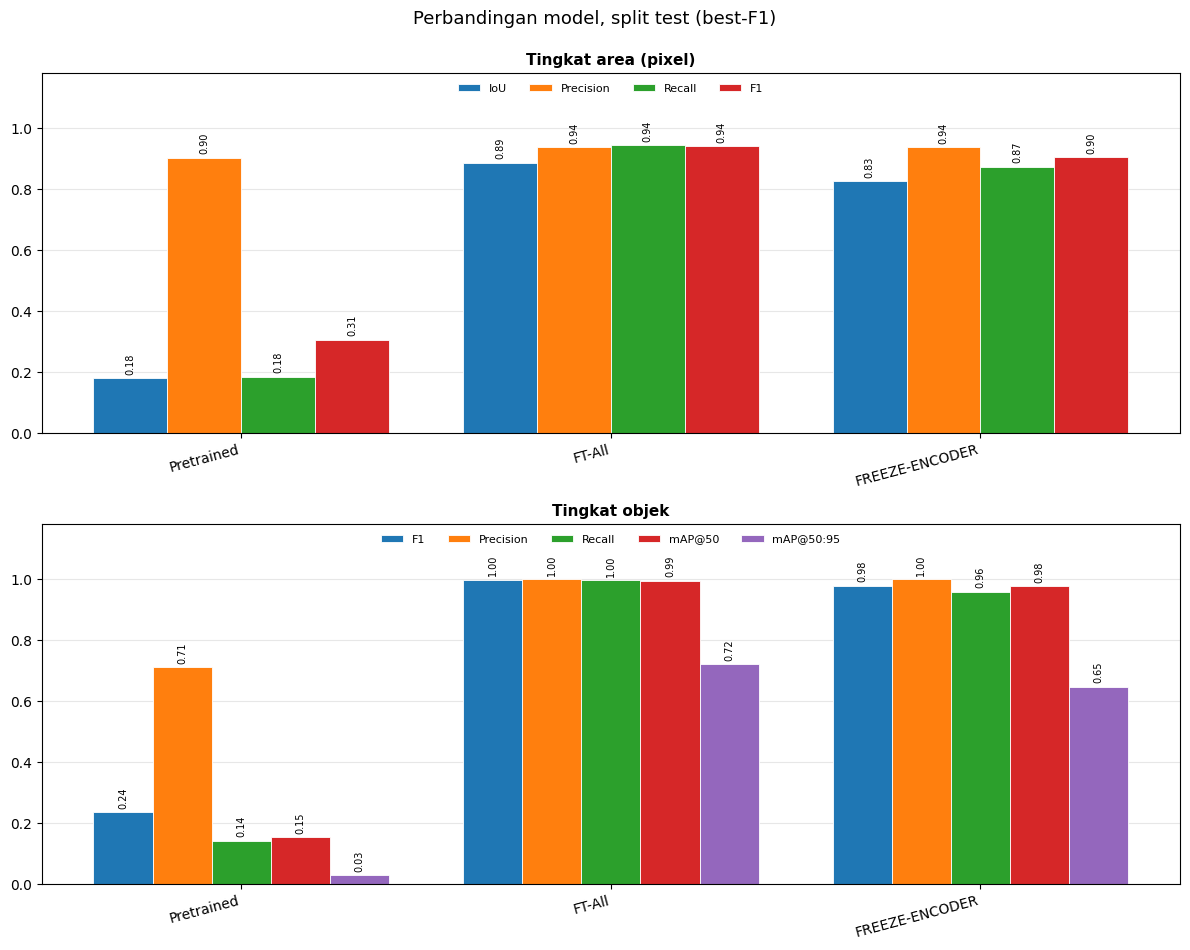

In [13]:
def grouped_bars(ax, metrics, title, split=MAIN_SPLIT):
    sub = RES[(RES.split == split) & (RES.operating_point == "best_f1")].set_index("model").loc[list(MODELS)]
    n = len(metrics); w = 0.8 / n; x = np.arange(len(MODELS))
    for i, mt in enumerate(metrics):
        vals = sub[mt].values.astype(float)
        bars = ax.bar(x + (i - (n - 1) / 2) * w, vals, w, label=NICE[mt], edgecolor="white", linewidth=0.6)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.012, f"{v:.2f}", ha="center", va="bottom", fontsize=7, rotation=90)
    ax.set_xticks(x); ax.set_xticklabels(list(MODELS), rotation=15, ha="right")
    ax.set_ylim(0, 1.18); ax.set_title(title, fontsize=11, fontweight="bold")
    ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
    ax.legend(ncol=n, fontsize=8, loc="upper center", frameon=False, bbox_to_anchor=(0.5, 1.0))

fig, axs = plt.subplots(2, 1, figsize=(12, 9.5))
grouped_bars(axs[0], ["Pixel_IoU", "Pixel_Precision", "Pixel_Recall", "Pixel_F1"], "Tingkat area (pixel)")
grouped_bars(axs[1], ["Obj_F1", "Obj_Precision", "Obj_Recall", "mAP50", "mAP50_95"], "Tingkat objek")
fig.suptitle(f"Perbandingan model, split {MAIN_SPLIT} (best-F1)", fontsize=13, y=0.995)
plt.tight_layout(); plt.savefig(OUT_DIR / "comparison_bar.png", dpi=200, bbox_inches="tight"); plt.show()

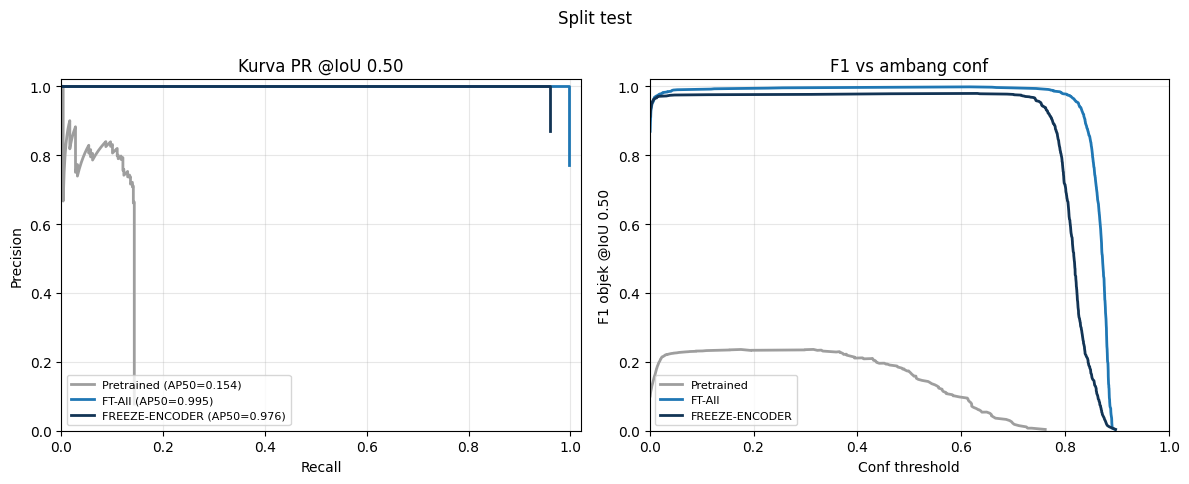

In [14]:
# Kurva Precision-Recall objek @IoU 0.50 (kiri) + F1 vs conf threshold (kanan)
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8))
for m in MODELS:
    ev = EVAL[m][MAIN_SPLIT]
    c, r, p = pr_curve(ev["conf"], ev["tp"][:, 0], ev["nGT"]); ap50 = ap_per_thr(ev)[0]
    f1 = 2 * p * r / np.maximum(p + r, 1e-16)
    axs[0].plot(r, p, color=COLORS[m], lw=2, label=f"{m} (AP50={ap50:.3f})")
    axs[1].plot(c, f1, color=COLORS[m], lw=2, label=m)
axs[0].set(xlabel="Recall", ylabel="Precision", xlim=(0, 1.02), ylim=(0, 1.02), title="Kurva PR @IoU 0.50")
axs[1].set(xlabel="Conf threshold", ylabel="F1 objek @IoU 0.50", xlim=(0, 1), ylim=(0, 1.02), title="F1 vs ambang conf")
for a in axs: a.grid(alpha=0.3); a.legend(fontsize=8, loc="lower left")
fig.suptitle(f"Split {MAIN_SPLIT}", y=1.0); plt.tight_layout()
plt.savefig(OUT_DIR / "pr_curves.png", dpi=200, bbox_inches="tight"); plt.show()

## 7. Grafik perbandingan
Satu panel untuk tingkat area dan satu untuk tingkat objek (batang dikelompokkan per model, warna konsisten), disusul kurva Precision–Recall dan F1 vs ambang conf.

## 8. Visualisasi berdampingan: Ground Truth | Baseline | Fine-tuning All | Fine-tuning Freeze Encoder
Setiap halaman ditampilkan dalam satu baris dengan urutan **Ground Truth → Pretrained (baseline) → FT-All → FT-FREEZE-ENCODER**, pada gambar yang sama.
Hijau = ground truth, merah = baseline, biru = FT-All. Prediksi memakai conf ≥ ambang best-F1 tiap model; judul panel memuat jumlah GT/prediksi dan F1 objek @IoU 0,50 untuk halaman tersebut.

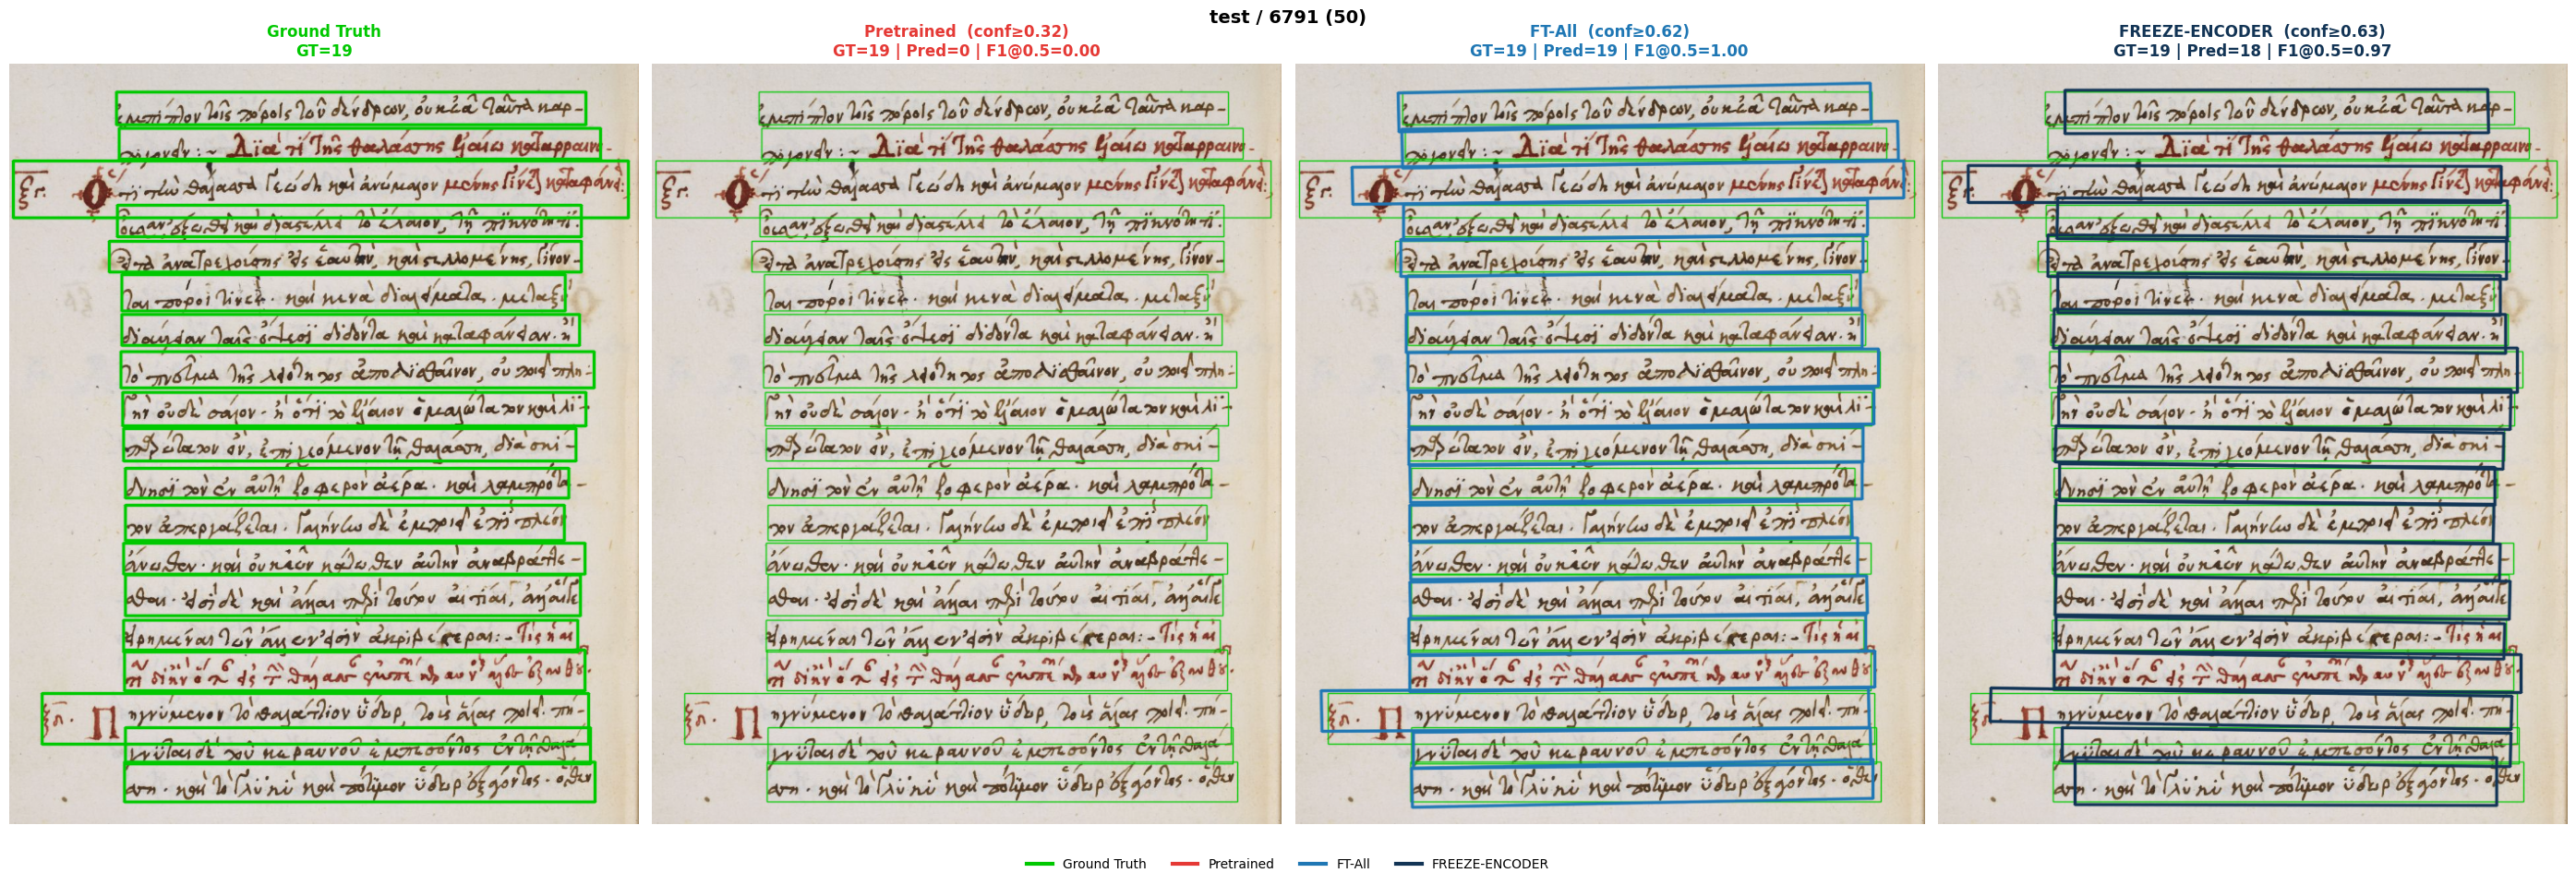

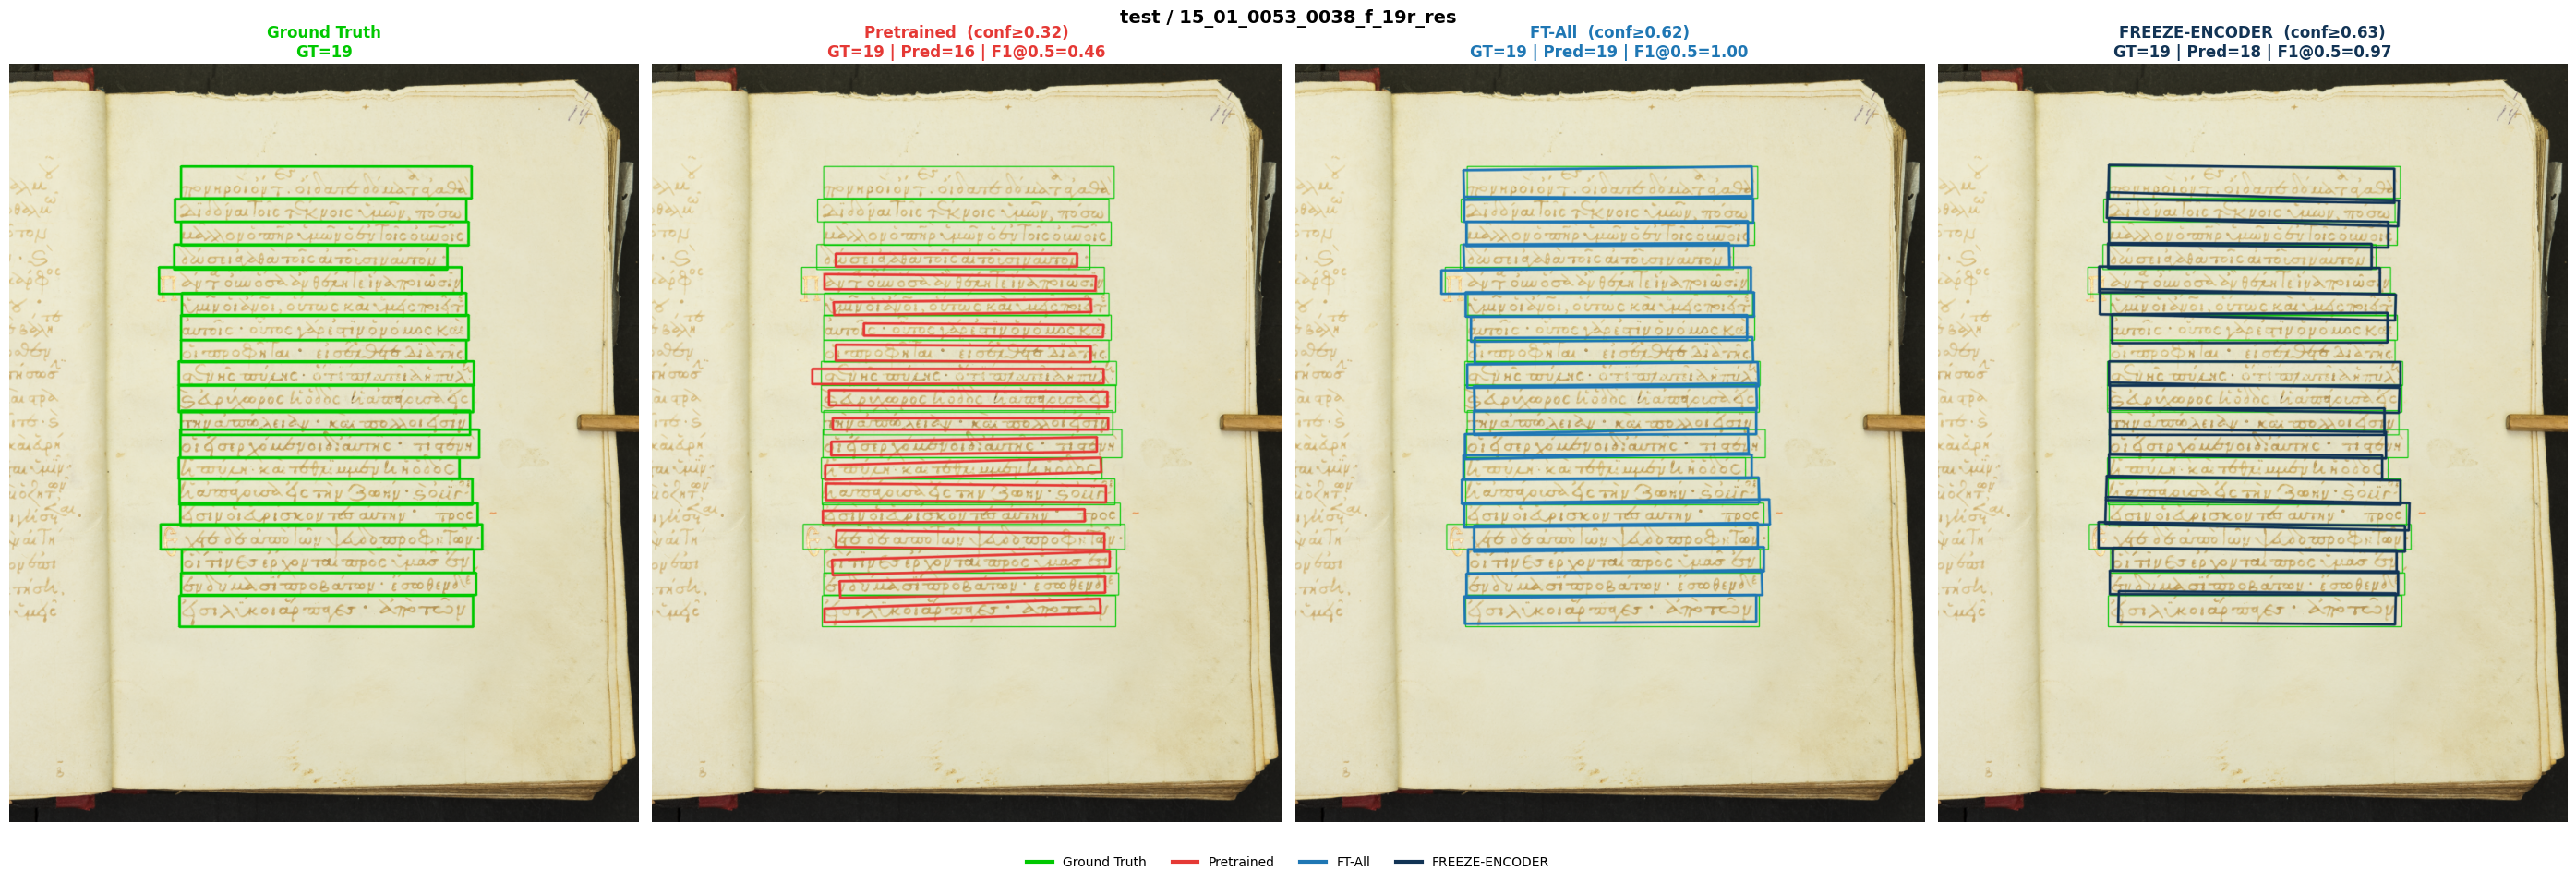

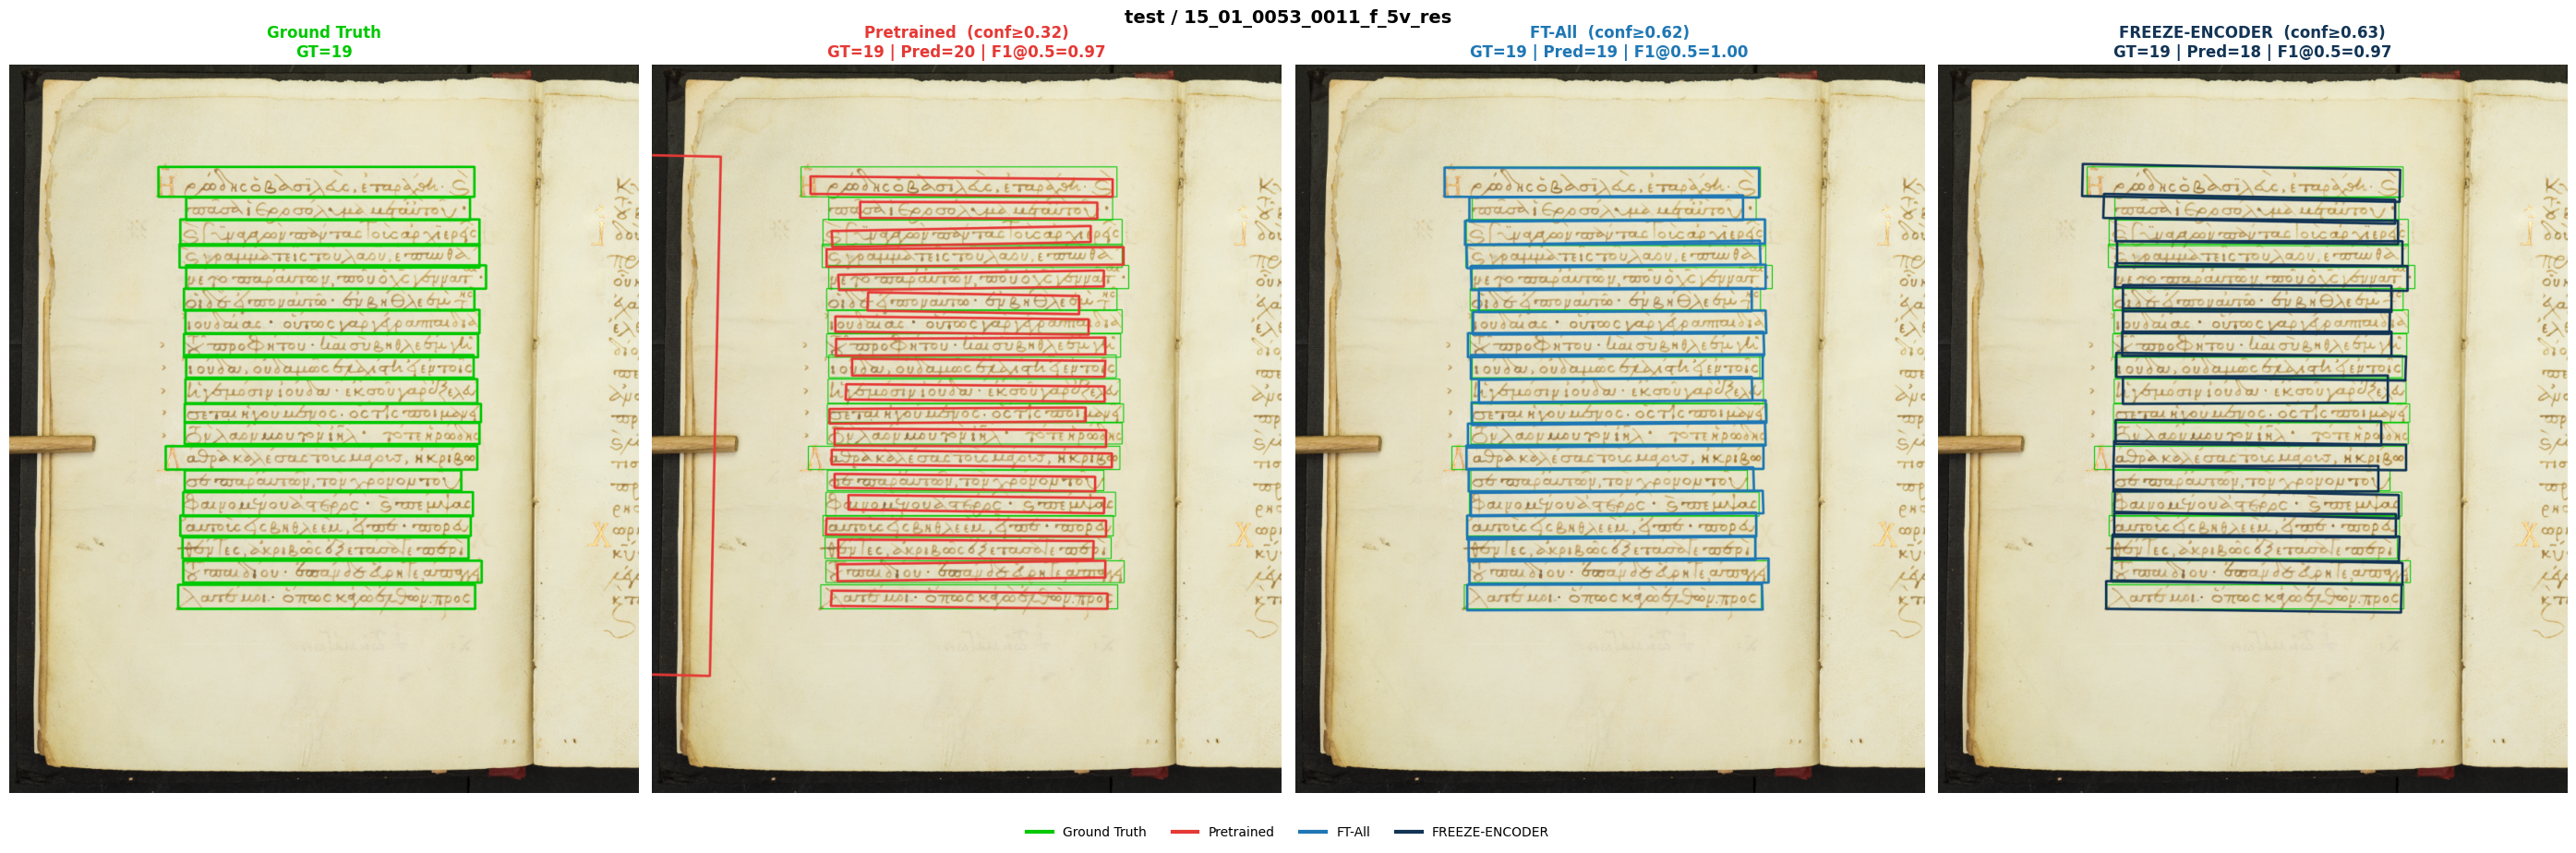

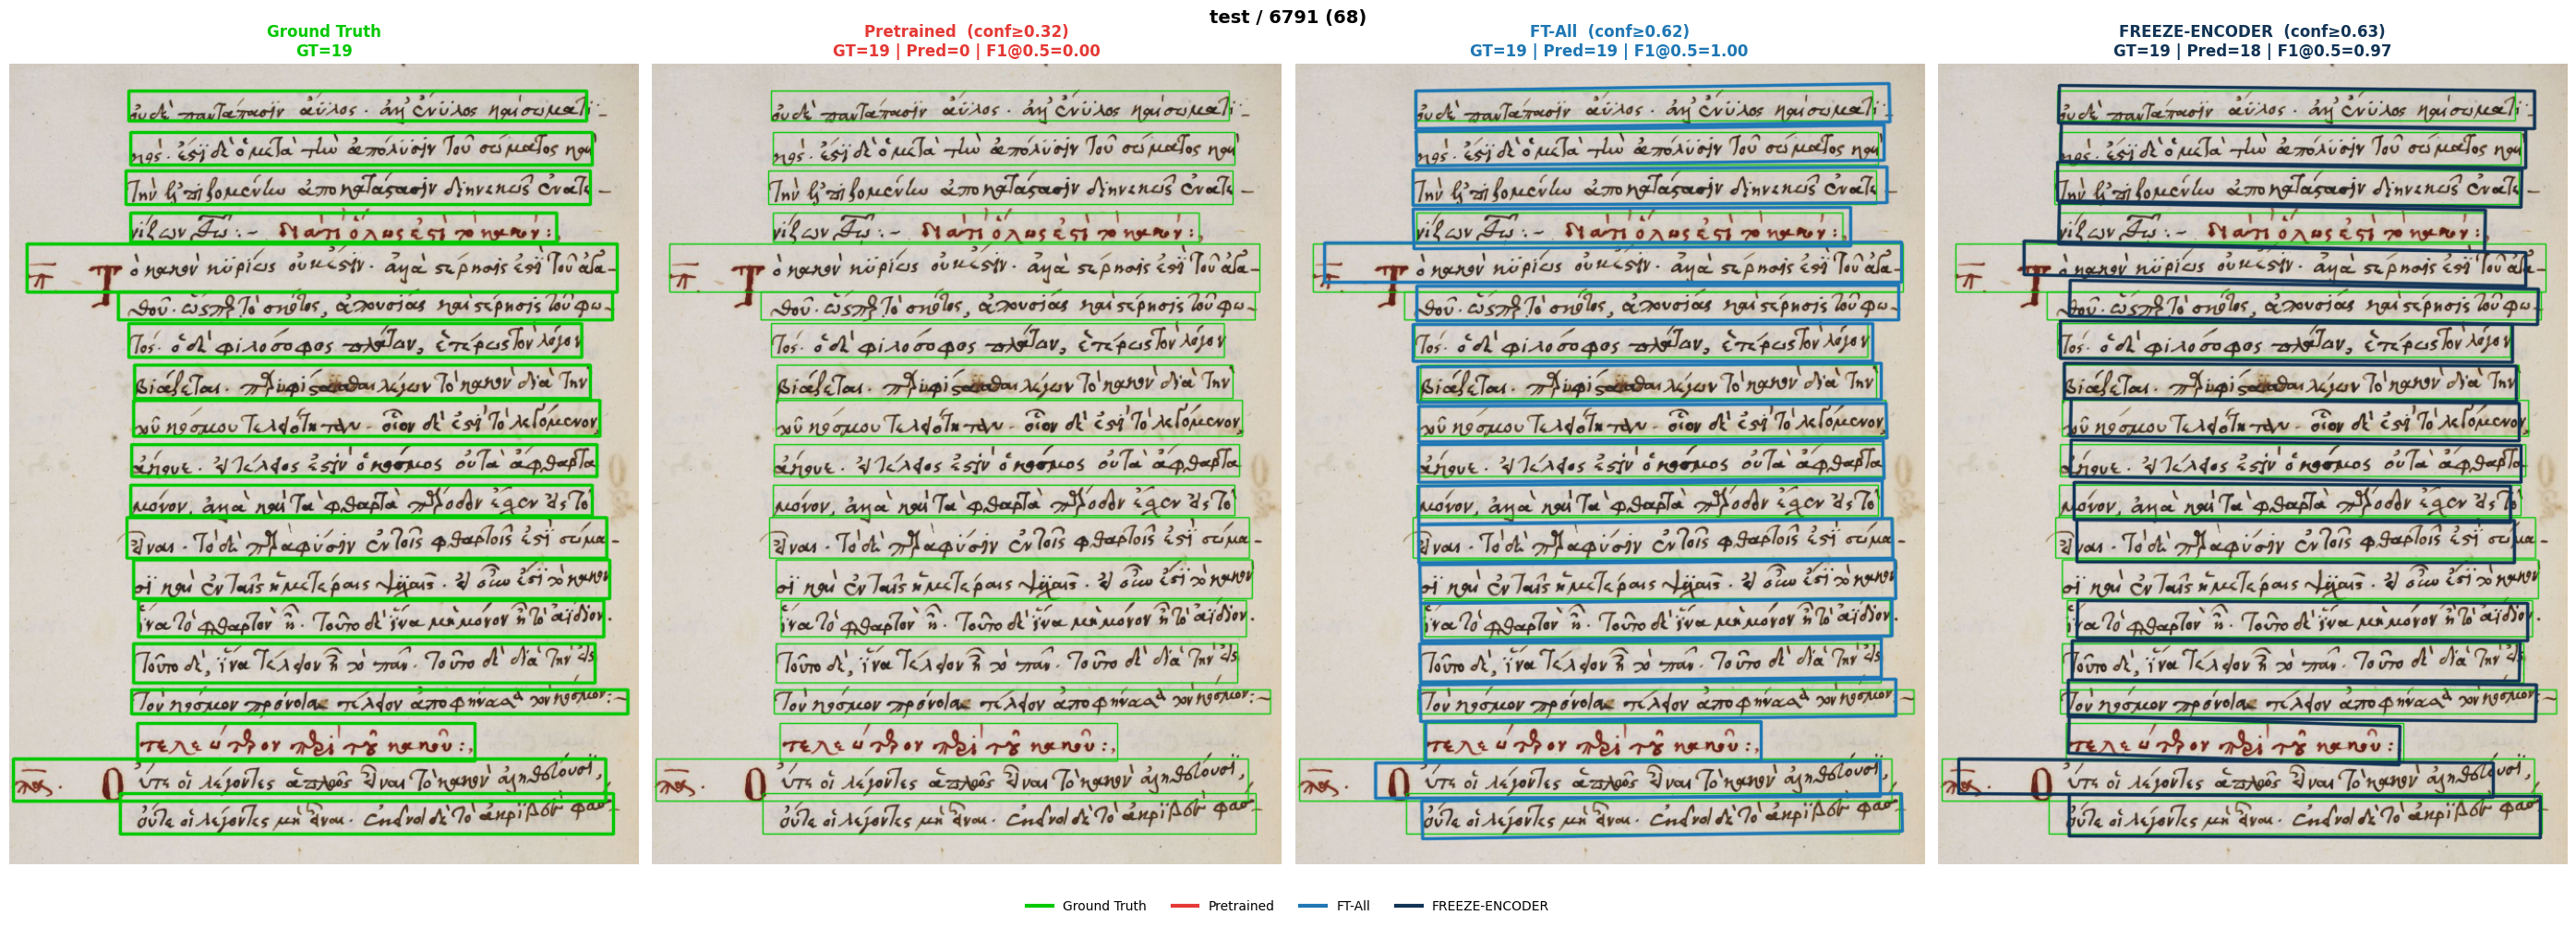

In [15]:
hex2bgr = lambda h: tuple(int(h[i:i + 2], 16) for i in (5, 3, 1))     # cv2 memakai BGR
OV_BGR  = {k: hex2bgr(v) for k, v in OVERLAY.items()}

def draw(img, quads, color, thick):
    for q in quads: cv2.polylines(img, [np.round(q).astype(np.int32)], True, color, thick, cv2.LINE_AA)

def page_f1(d, G, thr):
    """F1 objek @IoU 0.50 untuk satu halaman pada ambang conf `thr`."""
    Q = d["quads"][d["conf"] >= thr]
    tp, _ = match_image(rot_iou_matrix(Q, G), IOU_THRS[:1])
    TP = int(tp[:, 0].sum()) if len(Q) else 0
    P = TP / len(Q) if len(Q) else 0.0; R = TP / len(G) if len(G) else 0.0
    return 2 * P * R / (P + R) if P + R else 0.0

thr_of  = {m: RES[(RES.split == MAIN_SPLIT) & (RES.model == m) & (RES.operating_point == "best_f1")].Conf_threshold.iloc[0] for m in MODELS}
path_of = {p.stem: p for p in IMG_PATHS[MAIN_SPLIT]}
pred_of = {m: {d["stem"]: d for d in PRED[m][MAIN_SPLIT]} for m in MODELS}

def compare_side_by_side(stem, split=MAIN_SPLIT):
    base = cv2.imread(str(path_of[stem]), cv2.IMREAD_COLOR)
    H, W = base.shape[:2]; sc = min(1.0, 1000 / max(W, H)); thick = max(2, int(max(W, H) * sc / 450))
    base = cv2.resize(base, None, fx=sc, fy=sc, interpolation=cv2.INTER_AREA)
    ar = base.shape[0] / base.shape[1]
    G = GT[split][stem]
    ncol = 1 + len(MODELS)
    fig, axs = plt.subplots(1, ncol, figsize=(7 * ncol, 7 * ar + 1.0))

    # Panel 1: Ground Truth
    im = base.copy(); draw(im, G * sc, OV_BGR["Ground Truth"], thick)
    axs[0].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    axs[0].set_title(f"Ground Truth\nGT={len(G)}", fontsize=12, color=OVERLAY["Ground Truth"], fontweight="bold")
    cv2.imwrite(str(VIS_DIR / f"{split}_{stem}_GroundTruth.jpg"), im)

    # Panel 2..n: Baseline, lalu FT-All (urutan mengikuti MODELS)
    for ax, m in zip(axs[1:], MODELS):
        d = pred_of[m][stem]; Q = d["quads"][d["conf"] >= thr_of[m]]
        im = base.copy()
        if OVERLAY_GT_ON_PRED: draw(im, G * sc, OV_BGR["Ground Truth"], max(1, thick - 1))
        draw(im, Q * sc, OV_BGR[m], thick)
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{m}  (conf≥{thr_of[m]:.2f})\nGT={len(G)} | Pred={len(Q)} | F1@0.5={page_f1(d, G, thr_of[m]):.2f}",
                     fontsize=12, color=OVERLAY[m], fontweight="bold")
        cv2.imwrite(str(VIS_DIR / f"{split}_{stem}_{re.sub(r'[^A-Za-z0-9]+', '_', m)}.jpg"), im)

    for ax in axs: ax.axis("off")
    fig.suptitle(f"{split} / {stem}", fontsize=14, fontweight="bold")
    fig.legend(handles=[Line2D([0], [0], color=OVERLAY[n], lw=3, label=n) for n in ["Ground Truth", *MODELS]],
               loc="lower center", ncol=ncol, frameon=False, bbox_to_anchor=(0.5, -0.02))
    plt.tight_layout(); plt.show()

rng = random.Random(SEED)
stems_with_gt = [d["stem"] for d in PRED[BASE][MAIN_SPLIT] if len(GT[MAIN_SPLIT][d["stem"]])]
for stem in rng.sample(stems_with_gt, min(N_VIS, len(stems_with_gt))):
    compare_side_by_side(stem)